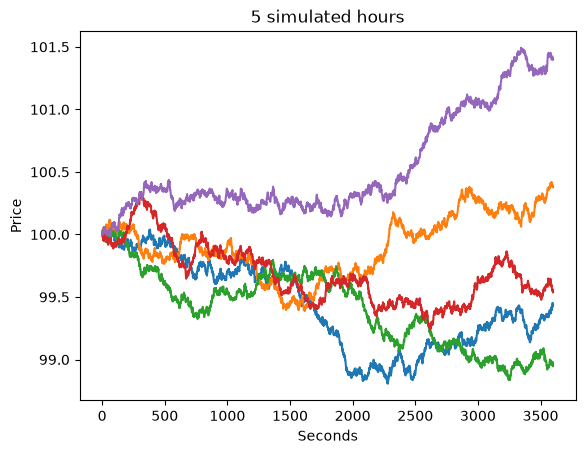

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.simulation import simulate_price

rng = np.random.default_rng(42)

for _ in range(5):
    plt.plot(simulate_price(rng))

plt.xlabel("Seconds")
plt.ylabel("Price")
plt.title("5 simulated hours")
plt.show()

0.5776204822605802


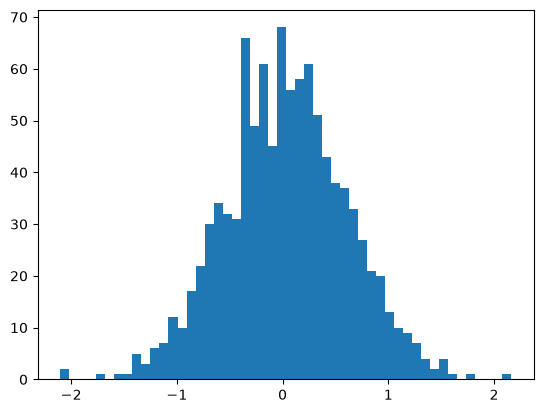

In [2]:
moves = [simulate_price(rng)[-1] - 100 for _ in range(1000)]
print(np.std(moves))
plt.hist(moves, bins=50)
plt.show()

In [3]:
from src.simulation import fill_probability

for d in [0, 0.005, 0.01, 0.02, 0.05]:
    print(d, round(fill_probability(d), 3))

0 0.5
0.005 0.303
0.01 0.184
0.02 0.068
0.05 0.003


In [4]:
rng = np.random.default_rng(42)
p = fill_probability(0.01)          # 0.184

fills = rng.random(3600) < p        # True/False for each of the 3,600 seconds
print(fills[:10])                   # the first 10 seconds
print(fills.sum())                  # how many fills in the hour

[False False False False  True False False False  True False]
682


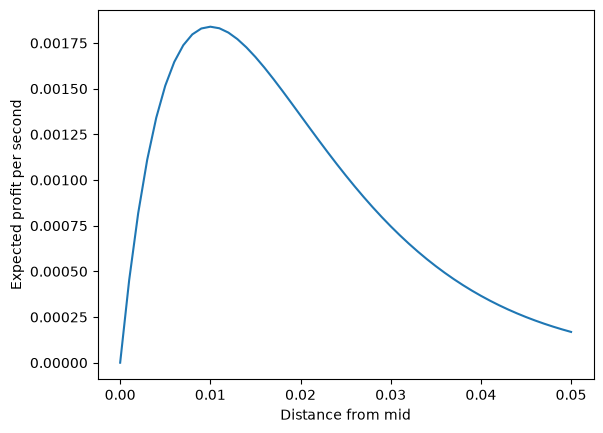

0.01


In [5]:
distances = np.linspace(0, 0.05, 51)
profit = distances * fill_probability(distances)

plt.plot(distances, profit)
plt.xlabel("Distance from mid")
plt.ylabel("Expected profit per second")
plt.show()

print(distances[profit.argmax()])

            mid  inventory        cash       pnl
3595  99.453225          2 -198.622321  0.284128
3596  99.448949          2 -198.622321  0.275577
3597  99.443238          1  -99.163372  0.279865
3598  99.425488          1  -99.163372  0.262116
3599  99.439449          1  -99.163372  0.276077


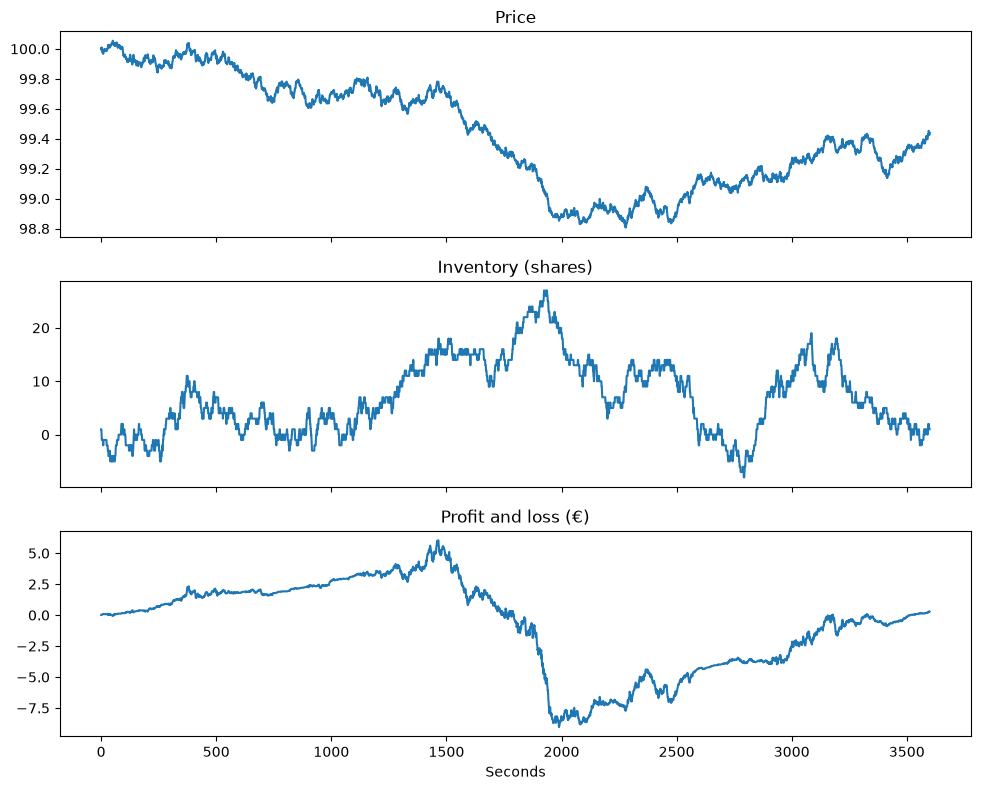

In [6]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

rng = np.random.default_rng(42)
prices = simulate_price(rng)
result = run_market_maker(rng, prices)

print(result.tail())

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
result["mid"].plot(ax=axes[0], title="Price")
result["inventory"].plot(ax=axes[1], title="Inventory (shares)")
result["pnl"].plot(ax=axes[2], title="Profit and loss (€)")
plt.xlabel("Seconds")
plt.tight_layout()
plt.show()

Average PnL per hour: 13.35
Std of PnL: 13.52
Share of losing hours: 0.12
Worst hour: -46.5
Average max inventory: 40.2


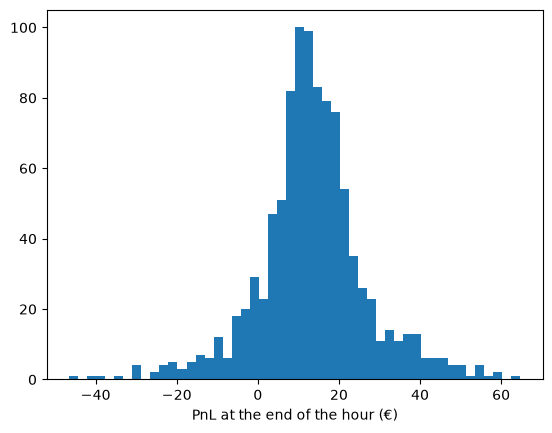

In [7]:
final_pnl = []
max_inventory = []

for _ in range(1000):
    prices = simulate_price(rng)
    result = run_market_maker(rng, prices)
    final_pnl.append(result["pnl"].iloc[-1])
    max_inventory.append(result["inventory"].abs().max())

final_pnl = np.array(final_pnl)

print("Average PnL per hour:", final_pnl.mean().round(2))
print("Std of PnL:", final_pnl.std().round(2))
print("Share of losing hours:", (final_pnl < 0).mean().round(2))
print("Worst hour:", final_pnl.min().round(2))
print("Average max inventory:", np.mean(max_inventory).round(1))

plt.hist(final_pnl, bins=50)
plt.xlabel("PnL at the end of the hour (€)")
plt.show()

In [9]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

def evaluate(skew, n_hours=300, seed=1):
    rng = np.random.default_rng(seed)
    pnls, max_inv = [], []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, skew=skew)
        pnls.append(result["pnl"].iloc[-1])
        max_inv.append(result["inventory"].abs().max())
    pnls = np.array(pnls)
    return {
        "skew": skew,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Profit / risk": pnls.mean() / pnls.std(),
        "Losing hours": (pnls < 0).mean(),
        "Worst hour": pnls.min(),
        "Avg max inventory": np.mean(max_inv),
    }

skews = [0, 0.0001, 0.0002, 0.0005, 0.001, 0.002]
results = pd.DataFrame([evaluate(s) for s in skews])
print(results.round(4))

     skew  Average PnL      Std  Profit / risk  Losing hours  Worst hour  \
0  0.0000      11.9964  13.9013         0.8630        0.1567    -50.4679   
1  0.0001      12.9384   4.0894         3.1639        0.0000      2.1573   
2  0.0002      13.0277   2.8941         4.5014        0.0000      5.1706   
3  0.0005      12.9830   1.8072         7.1842        0.0000      7.5514   
4  0.0010      12.8813   1.2367        10.4158        0.0000      9.2192   
5  0.0020      12.5733   0.8878        14.1625        0.0000      9.8756   

   Avg max inventory  
0            41.4367  
1            16.9867  
2            13.0533  
3             9.0467  
4             6.7933  
5             4.9633  


In [10]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.simulation import simulate_price, run_market_maker

def evaluate(skew, n_hours=300, seed=1):
    rng = np.random.default_rng(seed)
    pnls, max_inv = [], []
    for _ in range(n_hours):
        prices = simulate_price(rng)
        result = run_market_maker(rng, prices, skew=skew)
        pnls.append(result["pnl"].iloc[-1])
        max_inv.append(result["inventory"].abs().max())
    pnls = np.array(pnls)
    return {
        "skew": skew,
        "Average PnL": pnls.mean(),
        "Std": pnls.std(),
        "Profit / risk": pnls.mean() / pnls.std(),
        "Losing hours": (pnls < 0).mean(),
        "Worst hour": pnls.min(),
        "Avg max inventory": np.mean(max_inv),
    }

skews = [0.002, 0.005, 0.01, 0.02]
results = pd.DataFrame([evaluate(s) for s in skews])
print(results.round(4))

    skew  Average PnL     Std  Profit / risk  Losing hours  Worst hour  \
0  0.002      12.5733  0.8878        14.1625           0.0      9.8756   
1  0.005      11.5663  0.5991        19.3069           0.0      9.6573   
2  0.010       9.3455  0.4208        22.2098           0.0      8.1543   
3  0.020       2.2481  0.3432         6.5502           0.0      1.2985   

   Avg max inventory  
0             4.9633  
1             3.0867  
2             2.0000  
3             1.0000  
